---
title: "Implementación — Parte I"
subtitle: "Modelo de Programación Lineal para Selección de Preguntas"
description: "Notebook con implementación en scipy y PuLP del modelo LP/ILP, visualizaciones y análisis de sensibilidad."
categories: [Parte I, Notebook, LP, ILP, Python]
image: images/parte1_thumb.svg
format:
  html:
    code-links:
      - text: Descargar notebook (.ipynb)
        icon: file-earmark-arrow-down
        href: https://github.com/meaguirre3/Optimizacion/blob/main/parte1_implementacion.ipynb
      - text: Ver en GitHub
        icon: github
        href: https://github.com/meaguirre3/Optimizacion/blob/main/parte1_implementacion.ipynb
        target: _blank
    code-fold: false
    code-tools: true
---

## Instalación de dependencias

Ejecute esta celda para instalar las librerías necesarias en el kernel actual y garantizar la reproducibilidad del notebook.

In [1]:
# PuLP se fija a <4: la versión 4.x cambió la API (LpVariable(..., cat=...) ya no funciona)
%pip install -q --disable-pip-version-check numpy scipy matplotlib "pulp<4"

Note: you may need to restart the kernel to use updated packages.


## Implementación en Python con visualización de resultados

Este notebook presenta la implementación computacional del modelo de programación lineal (LP) y su extensión binaria (ILP) para la selección óptima de preguntas en un chatbot conversacional, tal como se formula en la Parte I del informe.

## 1. Datos del problema

Definimos los parámetros de las 9 preguntas candidatas y las restricciones del sistema.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# --- Parámetros de las preguntas candidatas ---
preguntas = ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9']
categorias = ['Clarificación', 'Clarificación', 'Clarificación',
              'Preferencias', 'Preferencias', 'Preferencias',
              'Objetivos', 'Objetivos', 'Objetivos']

r = np.array([0.90, 0.80, 0.72, 0.89, 0.80, 0.70, 0.92, 0.77, 0.75])  # relevancia
g = np.array([0.90, 0.72, 0.78, 0.84, 0.76, 0.67, 0.88, 0.80, 0.68])  # ganancia de información
a = np.array([1.60, 1.10, 0.95, 1.40, 1.10, 0.85, 1.70, 1.20, 0.85])  # carga cognitiva
l = np.array([0.75, 0.55, 0.70, 0.80, 0.45, 0.40, 1.00, 0.65, 0.50])  # latencia

# Utilidad de cada pregunta: u_i = 0.55*r_i + 0.45*g_i - 0.08*a_i
u = 0.55 * r + 0.45 * g - 0.08 * a

# Restricciones del sistema
M = 4      # máximo de preguntas
B = 4.70   # presupuesto de carga cognitiva
L = 2.80   # presupuesto de latencia
m_k = 0.70 # cobertura mínima por categoría

print('Utilidades calculadas:')
for i in range(9):
    print(f'  {preguntas[i]} ({categorias[i]:15s}): u = {u[i]:.4f}')

Utilidades calculadas:
  Q1 (Clarificación  ): u = 0.7720
  Q2 (Clarificación  ): u = 0.6760
  Q3 (Clarificación  ): u = 0.6710
  Q4 (Preferencias   ): u = 0.7555
  Q5 (Preferencias   ): u = 0.6940
  Q6 (Preferencias   ): u = 0.6185
  Q7 (Objetivos      ): u = 0.7660
  Q8 (Objetivos      ): u = 0.6875
  Q9 (Objetivos      ): u = 0.6505


## 2. Modelo continuo (LP) con `scipy.optimize.linprog`

Resolvemos el programa lineal relajado donde $x_i \in [0, 1]$.

In [3]:
n = 9

# linprog minimiza, así que negamos la utilidad para maximizar
c_obj = -u

# --- Restricciones de desigualdad (A_ub @ x <= b_ub) ---
A_ub = [
    np.ones(n),   # sum(x_i) <= M
    a,            # sum(a_i * x_i) <= B
    l,            # sum(l_i * x_i) <= L
    # Cobertura mínima: sum(x_i en I_k) >= m_k  -->  -sum(x_i en I_k) <= -m_k
    np.array([-1,-1,-1, 0, 0, 0, 0, 0, 0]),  # -Clarificación <= -0.70
    np.array([ 0, 0, 0,-1,-1,-1, 0, 0, 0]),   # -Preferencias  <= -0.70
    np.array([ 0, 0, 0, 0, 0, 0,-1,-1,-1]),   # -Objetivos     <= -0.70
]
b_ub = [M, B, L, -m_k, -m_k, -m_k]

# Cotas: 0 <= x_i <= 1
bounds = [(0, 1)] * n

# Resolver
res_lp = linprog(c_obj, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')

print(f'Estado: {res_lp.message}')
print(f'Utilidad óptima LP: Z* = {-res_lp.fun:.4f}\n')
print('Asignaciones óptimas (proporción de sesiones):')
for i in range(n):
    print(f'  {preguntas[i]}: x = {res_lp.x[i]:.4f}')

Estado: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Utilidad óptima LP: Z* = 2.8348

Asignaciones óptimas (proporción de sesiones):
  Q1: x = 0.6500
  Q2: x = 0.0000
  Q3: x = 1.0000
  Q4: x = 1.0000
  Q5: x = 0.6500
  Q6: x = 0.0000
  Q7: x = 0.0000
  Q8: x = 0.0000
  Q9: x = 0.7000


## 3. Modelo binario (ILP) con PuLP

Resolvemos el programa lineal entero binario donde $y_i \in \{0, 1\}$.

In [4]:
from pulp import LpMaximize, LpProblem, LpVariable, lpSum, value, LpBinary

prob = LpProblem('Seleccion_Preguntas', LpMaximize)

# Variables binarias
y = [LpVariable(f'y_{i+1}', cat=LpBinary) for i in range(n)]

# Función objetivo
prob += lpSum(u[i] * y[i] for i in range(n)), 'Utilidad_Total'

# Restricciones
prob += lpSum(y[i] for i in range(n)) <= M, 'Max_Preguntas'
prob += lpSum(a[i] * y[i] for i in range(n)) <= B, 'Carga_Cognitiva'
prob += lpSum(l[i] * y[i] for i in range(n)) <= L, 'Latencia'
prob += lpSum(y[i] for i in range(3)) >= m_k, 'Cobertura_Clarificacion'      # Q1-Q3
prob += lpSum(y[i] for i in range(3, 6)) >= m_k, 'Cobertura_Preferencias'    # Q4-Q6
prob += lpSum(y[i] for i in range(6, 9)) >= m_k, 'Cobertura_Objetivos'       # Q7-Q9

prob.solve()

print(f'Estado: {prob.status} ({"Óptimo" if prob.status == 1 else "No óptimo"})')
print(f'Utilidad óptima ILP: Z* = {value(prob.objective):.4f}\n')

seleccionadas = []
print('Decisiones:')
for i in range(n):
    sel = int(value(y[i]))
    marca = '✓ Seleccionada' if sel == 1 else '  No seleccionada'
    print(f'  {preguntas[i]} (u={u[i]:.4f}): {marca}')
    if sel == 1:
        seleccionadas.append(i)

carga_usada = sum(a[i] for i in seleccionadas)
latencia_usada = sum(l[i] for i in seleccionadas)
print(f'\nRecursos utilizados:')
print(f'  Carga cognitiva: {carga_usada:.2f} / {B:.2f} (holgura: {B - carga_usada:.2f})')
print(f'  Latencia:        {latencia_usada:.2f} / {L:.2f} (holgura: {L - latencia_usada:.2f})')

Estado: 1 (Óptimo)
Utilidad óptima ILP: Z* = 2.8080

Decisiones:
  Q1 (u=0.7720):   No seleccionada
  Q2 (u=0.6760):   No seleccionada
  Q3 (u=0.6710): ✓ Seleccionada
  Q4 (u=0.7555): ✓ Seleccionada
  Q5 (u=0.6940): ✓ Seleccionada
  Q6 (u=0.6185):   No seleccionada
  Q7 (u=0.7660):   No seleccionada
  Q8 (u=0.6875): ✓ Seleccionada
  Q9 (u=0.6505):   No seleccionada

Recursos utilizados:
  Carga cognitiva: 4.65 / 4.70 (holgura: 0.05)
  Latencia:        2.60 / 2.80 (holgura: 0.20)


## 4. Visualización de resultados

### 4.1 Comparación de utilidades por pregunta

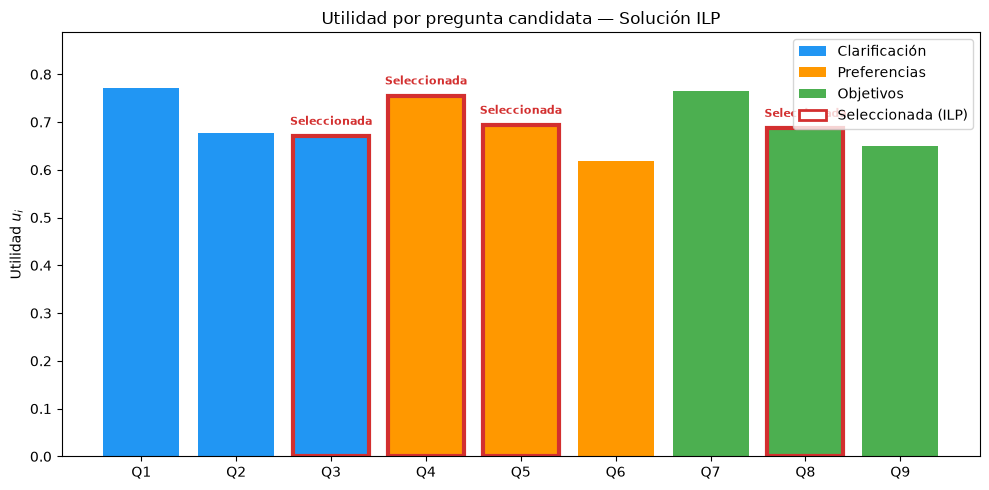

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

colores_cat = {'Clarificación': '#2196F3', 'Preferencias': '#FF9800', 'Objetivos': '#4CAF50'}
colores = [colores_cat[c] for c in categorias]
bordes = ['#D32F2F' if i in seleccionadas else 'none' for i in range(n)]
anchos = [3 if i in seleccionadas else 0 for i in range(n)]

bars = ax.bar(preguntas, u, color=colores, edgecolor=bordes, linewidth=anchos)

for i in seleccionadas:
    ax.annotate('Seleccionada', (i, u[i]), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=8, fontweight='bold', color='#D32F2F')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=k) for k, c in colores_cat.items()]
legend_elements.append(Patch(facecolor='white', edgecolor='#D32F2F', linewidth=2, label='Seleccionada (ILP)'))
ax.legend(handles=legend_elements, loc='upper right')

ax.set_ylabel('Utilidad $u_i$')
ax.set_title('Utilidad por pregunta candidata — Solución ILP')
ax.set_ylim(0, max(u) * 1.15)
plt.tight_layout()
plt.show()

### 4.2 Comparación LP vs ILP

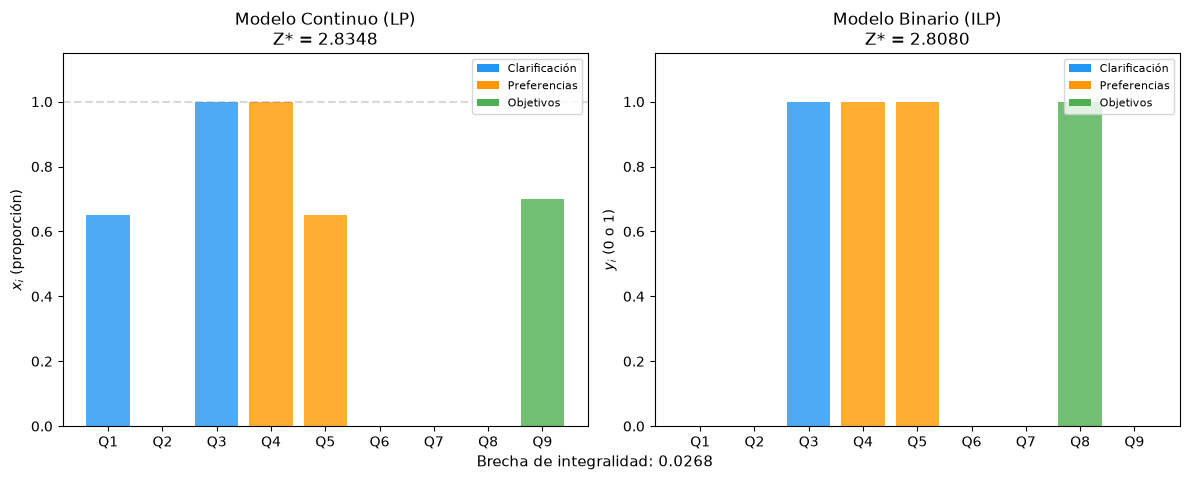

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico LP (continuo)
axes[0].bar(preguntas, res_lp.x, color=colores, alpha=0.8)
axes[0].set_ylabel('$x_i$ (proporción)')
axes[0].set_title(f'Modelo Continuo (LP)\nZ* = {-res_lp.fun:.4f}')
axes[0].set_ylim(0, 1.15)
axes[0].axhline(y=1, color='gray', linestyle='--', alpha=0.3)

# Gráfico ILP (binario)
y_vals = [int(value(y[i])) for i in range(n)]
axes[1].bar(preguntas, y_vals, color=colores, alpha=0.8)
axes[1].set_ylabel('$y_i$ (0 o 1)')
axes[1].set_title(f'Modelo Binario (ILP)\nZ* = {value(prob.objective):.4f}')
axes[1].set_ylim(0, 1.15)

for ax in axes:
    ax.legend(handles=[Patch(facecolor=c, label=k) for k, c in colores_cat.items()],
              loc='upper right', fontsize=8)

fig.suptitle(f'Brecha de integralidad: {-res_lp.fun - value(prob.objective):.4f}', fontsize=11, y=0.02)
plt.tight_layout()
plt.show()

### 4.3 Uso de recursos vs presupuesto

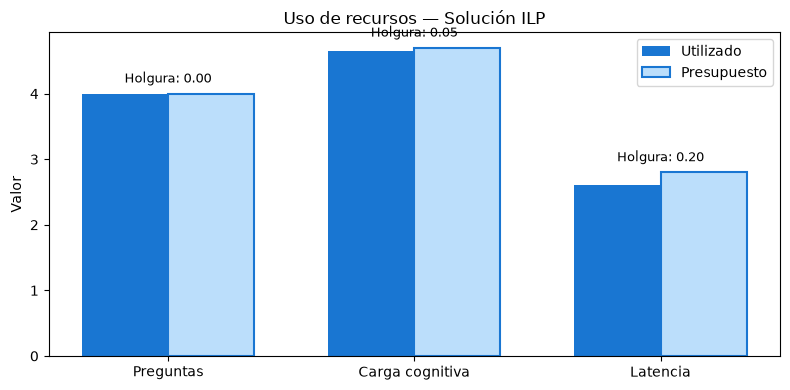

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))

recursos = ['Preguntas', 'Carga cognitiva', 'Latencia']
usados = [len(seleccionadas), carga_usada, latencia_usada]
presupuestos = [M, B, L]
holguras = [p - us for p, us in zip(presupuestos, usados)]

x_pos = np.arange(len(recursos))
width = 0.35

bars1 = ax.bar(x_pos - width/2, usados, width, label='Utilizado', color='#1976D2')
bars2 = ax.bar(x_pos + width/2, presupuestos, width, label='Presupuesto', color='#BBDEFB', edgecolor='#1976D2', linewidth=1.5)

for i, (us_val, h) in enumerate(zip(usados, holguras)):
    ax.annotate(f'Holgura: {h:.2f}', (i, max(us_val, presupuestos[i])),
                textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)

ax.set_xticks(x_pos)
ax.set_xticklabels(recursos)
ax.set_ylabel('Valor')
ax.set_title('Uso de recursos — Solución ILP')
ax.legend()
plt.tight_layout()
plt.show()

### 4.4 Análisis de sensibilidad

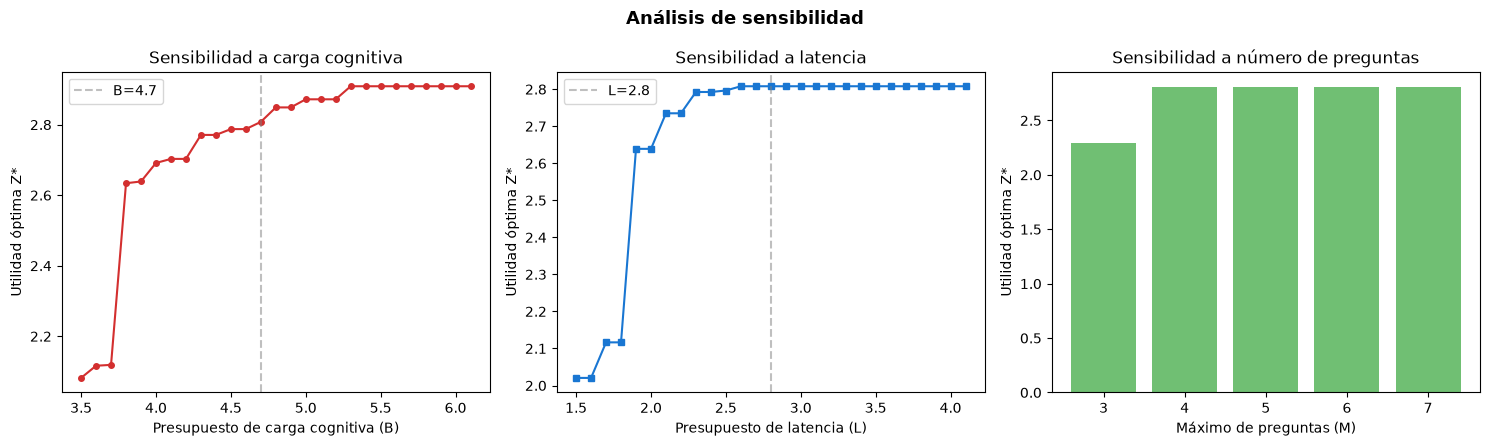

In [8]:
from pulp import PULP_CBC_CMD

def resolver_ilp_sens(M_val, B_val, L_val):
    p = LpProblem('Sens', LpMaximize)
    yv = [LpVariable(f'ys_{i}', cat=LpBinary) for i in range(n)]
    p += lpSum(u[i] * yv[i] for i in range(n))
    p += lpSum(yv[i] for i in range(n)) <= M_val
    p += lpSum(a[i] * yv[i] for i in range(n)) <= B_val
    p += lpSum(l[i] * yv[i] for i in range(n)) <= L_val
    p += lpSum(yv[i] for i in range(3)) >= m_k
    p += lpSum(yv[i] for i in range(3, 6)) >= m_k
    p += lpSum(yv[i] for i in range(6, 9)) >= m_k
    p.solve(PULP_CBC_CMD(msg=0))
    obj = value(p.objective)
    return float(obj) if obj is not None else 0.0

B_sens = [round(3.5 + i*0.1, 1) for i in range(27)]
Z_B = [resolver_ilp_sens(M, bv, L) for bv in B_sens]

L_sens = [round(1.5 + i*0.1, 1) for i in range(27)]
Z_L = [resolver_ilp_sens(M, B, lv) for lv in L_sens]

M_sens = [3, 4, 5, 6, 7]
Z_M = [resolver_ilp_sens(mv, B, L) for mv in M_sens]

# Filtrar infactibles
bx = [b for b, z in zip(B_sens, Z_B) if z > 0]
by = [z for z in Z_B if z > 0]
lx = [lv for lv, z in zip(L_sens, Z_L) if z > 0]
ly = [z for z in Z_L if z > 0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(bx, by, 'o-', color='#D32F2F', markersize=4)
axes[0].axvline(x=B, color='gray', linestyle='--', alpha=0.5, label=f'B={B}')
axes[0].set_xlabel('Presupuesto de carga cognitiva (B)')
axes[0].set_ylabel('Utilidad óptima Z*')
axes[0].set_title('Sensibilidad a carga cognitiva')
axes[0].legend()

axes[1].plot(lx, ly, 's-', color='#1976D2', markersize=4)
axes[1].axvline(x=L, color='gray', linestyle='--', alpha=0.5, label=f'L={L}')
axes[1].set_xlabel('Presupuesto de latencia (L)')
axes[1].set_ylabel('Utilidad óptima Z*')
axes[1].set_title('Sensibilidad a latencia')
axes[1].legend()

axes[2].bar([str(m) for m in M_sens], Z_M, color='#4CAF50', alpha=0.8)
axes[2].set_xlabel('Máximo de preguntas (M)')
axes[2].set_ylabel('Utilidad óptima Z*')
axes[2].set_title('Sensibilidad a número de preguntas')

plt.suptitle('Análisis de sensibilidad', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Resumen de resultados

| Modelo | Utilidad óptima | Preguntas seleccionadas | Herramienta |
|--------|:-:|:-:|:-:|
| Continuo (LP) | Z* ≈ 2.8348 | Asignaciones fraccionarias | `scipy.optimize.linprog` |
| Binario (ILP) | Z* = 2.8080 | Q3, Q4, Q5, Q8 | `PuLP` |

La brecha de integralidad es de apenas **0.0268**, confirmando que la relajación LP es una excelente aproximación al problema binario. Las restricciones más activas son la de carga cognitiva (holgura de 0.05) y la de máximo de preguntas (ajustada exactamente a 4).